In [1]:
from anemone.experiment import *
from anemone.transforms import Hankel
from anemone.physics import freespace_u0 as u0, refl_transverse_electric as rte
import matplotlib.pyplot as plt
import numpy as np

In [2]:
lp = Loop.square(25)

In [3]:
rx = Receiver()

In [4]:
class Forward:
    def __init__(self, source, receiver, frequency, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freq = frequency
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)
        self.device = torch.device('cpu')
        self.tolerance=tolerance

    @property
    def omega(self):
        return c.twopi*self.freq
    
    def forward(self):
        def wvlngth_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]
            tmp_u0 = u0(self.omega, lmb)
            intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, self.omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
            intg *= lmb**2 / tmp_u0
            return torch.squeeze(intg/c.fourpi)
        
        hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
        res = integrate_around_loop(self.source, self.receiver, hkl1)
        return res



    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None]
        self.thick = (thickness + 0j).to(self.device)[...,None]
        return self.forward().real*c.mu0

In [5]:
class Forward2:
    sofr = None
    def __init__(self, source, receiver, frequency, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freq = frequency
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        if self.rmin==0: self.rmin = 1e-2
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()
        self.pfield_dz = torch.abs(self.srcz-self.rz)[0]
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)[0]
        self.device = torch.device('cpu')
        self.tolerance=tolerance        

    @property
    def omega(self):
        return c.twopi*self.freq
    
    def forward(self):
        def wvlngth_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]
            tmp_u0 = u0(self.omega, lmb)
            cRTE = rte(self.sigma, self.thick, self.omega, lmb)
            intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, self.omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
            intg *= lmb**2 / tmp_u0
            return torch.squeeze(intg/c.fourpi)
        
        hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=16)
        r,HR = hkl1.range(self.rmin, self.rmax)
        if self.sofr is None:
            self.sofr = self.source.s_of_r(self.receiver, r)
        return - torch.einsum('...i,...i->...', HR, self.sofr)



    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None]
        self.thick = (thickness + 0j).to(self.device)[...,None]
        return self.forward()#.real*c.mu0

In [6]:
fwr = Forward(lp, rx, 2000)
fwr2 = Forward2(lp, rx, 2000)

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:127: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [7]:
lp = Loop.square(60)
rxs = Receiver(x=np.linspace(-75, 75, 61), y=np.linspace(-75, 75, 61))
rmin,rmax = lp.min_horizontal_distance(rxs), lp.max_horizontal_distance(rxs)
fwr3 = Forward2(lp, rxs, 2000)

In [8]:
bz = fwr3(np.array([0.1, 0.1]), np.array([40])).real.reshape(fwr3.receiver.shp[:-1])[..., 0]

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:140: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)


In [9]:
bz.shape

torch.Size([61, 61])

In [10]:
passthrough = lambda x: x
hkl1 = Hankel(passthrough, 1, smp_per_decade=16)
r,HR = hkl1.range(fwr3.rmin, fwr3.rmax)

In [11]:
rxs.x.shape

torch.Size([61, 61])

In [12]:
r.shape

torch.Size([71])

In [13]:
n_skip = len(r)//16

In [14]:
sofr = fwr3.sofr

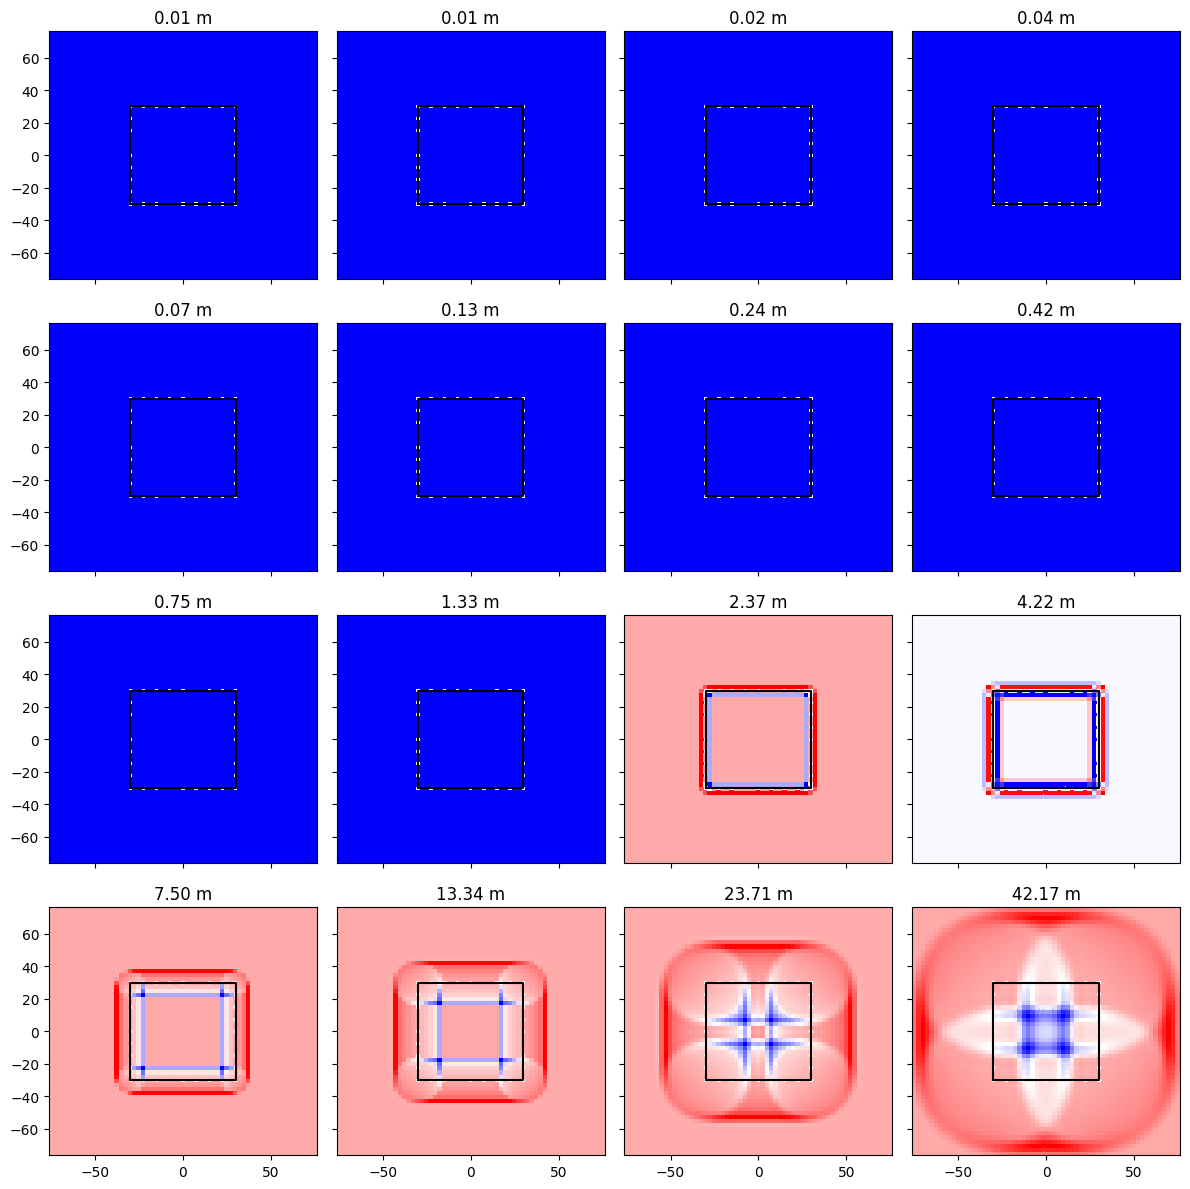

In [15]:
sofrcube = sofr.reshape(rxs.x.shape+r.shape)
fig,axs = plt.subplots(4,4, sharex=True, sharey=True, figsize=(12,12))
for i,ax in enumerate(axs.flatten()):
    ax.set_title(f'{r[i*n_skip]:0.2f} m')
    vlim = max(abs(sofrcube.real[:,:,i*n_skip].min()), abs(sofrcube.real[:,:,i*n_skip].max()))
    pcm=ax.pcolor(rxs.x, rxs.y, sofrcube.real[:,:,i*n_skip], cmap='bwr')
    ax.plot(lp.x, lp.y, 'k')
# plt.colorbar(pcm, ax=axs, orientation='horizontal')
plt.tight_layout()
# plt.pcolor(rxs.x, rxs.y, np.abs(sofrcube[:,:,150]))

C:\Users\au646858\AppData\Local\Temp\ipykernel_9312\2084946205.py:4: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[0])
C:\Users\au646858\AppData\Local\Temp\ipykernel_9312\2084946205.py:9: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[1])


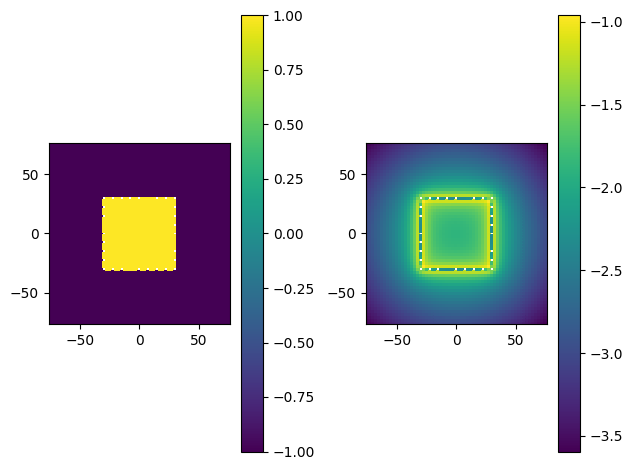

In [16]:
fig,axs=plt.subplots(1,2)
pcm=axs[0].pcolor(fwr3.receiver.x, fwr3.receiver.y, np.sign(bz))
# axs[0].plot(lp.x, lp.y, 'r')
plt.colorbar(pcm, ax=axs[0])
axs[0].set_aspect(1)

pcm=axs[1].pcolor(fwr3.receiver.x, fwr3.receiver.y, np.log10(np.abs(bz)))
# axs[1].plot(lp.x, lp.y, 'r')
plt.colorbar(pcm, ax=axs[1])
axs[1].set_aspect(1)
plt.tight_layout()
plt.show()